# 04 — Comparação de modelos

**Objetivo:** comparar famílias de algoritmos — regressão logística, Naive Bayes, SVM, rede neural (MLP), árvore de decisão e LightGBM —, cada uma com o perfil de pré-processamento adequado (notebook 03, seção 6), com **busca aleatória de hiperparâmetros** nos mesmos folds temporais.

> Só o treino (meses 0–5) é usado. Escolher o melhor entre várias tentativas nos mesmos folds dá uma estimativa levemente otimista; a avaliação honesta fica para o teste, no notebook 05.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/fraude-abertura-conta")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAIZ = Path(os.getenv("FRAUDE_RAIZ", RAIZ))
DATA_DIR = RAIZ / "data"
FIG_DIR = RAIZ / "reports" / "figures"

sys.path.insert(0, str(RAIZ))
from src.preprocessamento import ALVO, limpar
from src.validacao import validar
from src.perfis import pipeline_escala

treino = pd.read_parquet(DATA_DIR / "train.parquet")
assert treino["month"].between(0, 5).all()
print(f"{len(treino):,} linhas")


from src.experimentos import modelo_de, rodar_busca

794,989 linhas


In [2]:
from sklearn.linear_model import LogisticRegression

res_logistica = validar(modelo_de(lambda: pipeline_escala(LogisticRegression(max_iter=1000))), treino)
res_logistica.round(4)

,recall@5%FPR,PR-AUC,ROC AUC
fold,,,
0–2 → 3,0.5524,0.1399,0.9045
0–3 → 4,0.5379,0.1511,0.9005
0–4 → 5,0.5131,0.1600,0.8841
média,0.5345,0.1503,0.8964
desvio padrão,0.0199,0.0100,0.0108


## 1. Primeiro contato com o LightGBM

LightGBM com os hiperparâmetros **padrão**, no perfil de árvores (ausentes como `NaN`, categorias nativas, sem escala), **com e sem** undersampling — antes de qualquer ajuste.

In [3]:
from lightgbm import LGBMClassifier
from src.perfis import pipeline_arvores


def lgbm_padrao():
    return LGBMClassifier(random_state=42, verbose=-1)


res_lgbm = validar(modelo_de(lambda: pipeline_arvores(lgbm_padrao())), treino)
res_lgbm_under = validar(modelo_de(lambda: pipeline_arvores(lgbm_padrao(), undersampling=True)), treino)

comparacao = pd.DataFrame({
    "regressão logística": res_logistica.loc["média"],
    "LightGBM (padrão, todos os dados)": res_lgbm.loc["média"],
    "LightGBM (padrão, undersampling 1:10)": res_lgbm_under.loc["média"],
}).T
display(res_lgbm.round(4))
comparacao.style.format(precision=4, decimal=",")

,recall@5%FPR,PR-AUC,ROC AUC
fold,,,
0–2 → 3,0.5323,0.1255,0.9045
0–3 → 4,0.5475,0.1386,0.9047
0–4 → 5,0.5237,0.1559,0.8905
média,0.5345,0.1400,0.8999
desvio padrão,0.0120,0.0152,0.0081


,recall@5%FPR,PR-AUC,ROC AUC
regressão logística,"0,5345","0,1503","0,8964"
"LightGBM (padrão, todos os dados)","0,5345","0,1400","0,8999"
"LightGBM (padrão, undersampling 1:10)","0,5459","0,1675","0,9038"


**Conclusão:**

- Com hiperparâmetros **padrão**, o LightGBM com todos os dados **empata** com a regressão logística no recall (0,5345) e fica **abaixo na PR-AUC** (0,140 vs. 0,150).
- **Com undersampling, o LightGBM padrão supera a logística em todas as métricas:** recall de 0,546, PR-AUC de 0,168 (+11%) e ROC AUC de 0,904.
- Hipótese: com poucas árvores (100) e sem peso para a classe rara, o modelo treinado com 1% de fraudes concentra o esforço nos legítimos; o undersampling aumenta o peso relativo das fraudes. Com mais árvores ou `scale_pos_weight`, o cenário pode mudar — por isso o undersampling entra na busca como **mais um hiperparâmetro**.

## 2. Busca aleatória de hiperparâmetros

Para cada modelo, definimos uma distribuição para cada hiperparâmetro e sorteamos combinações (`ParameterSampler`, semente fixa). Cada candidato é avaliado nos 3 folds temporais; o critério é o recall médio a 5% de FPR. Os resultados são gravados em `reports/busca_04_modelos.csv` à medida que terminam.

Começamos pela regressão logística, para testar a infraestrutura: o único hiperparâmetro relevante é `C` (o inverso da força da regularização L2).

In [4]:
from scipy.stats import loguniform, randint, uniform
from sklearn.kernel_approximation import Nystroem
from sklearn.model_selection import ParameterSampler
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

from src.perfis import SEMENTE, pipeline_arvores

ARQ_BUSCA = RAIZ / "reports" / "busca_04_modelos.csv"
os.environ["PYTHONPATH"] = str(RAIZ) + os.pathsep + os.environ.get("PYTHONPATH", "")


# ---------- Fábricas: hiperparâmetros -> pipeline completo ----------
def fabrica_logistica(C):
    return pipeline_escala(LogisticRegression(C=C, max_iter=1000))


def fabrica_naive_bayes(var_smoothing):
    return pipeline_escala(GaussianNB(var_smoothing=var_smoothing))


def fabrica_svm(gamma, n_components, C):
    # Aproximação do kernel RBF (Nystroem) + SVM linear: viável com dezenas de milhares de linhas
    svm = make_pipeline(
        Nystroem(kernel="rbf", gamma=gamma, n_components=n_components, random_state=SEMENTE),
        LinearSVC(C=C, random_state=SEMENTE),
    )
    return pipeline_escala(svm)


def fabrica_mlp(hidden_layer_sizes, alpha, learning_rate_init, batch_size):
    return pipeline_escala(MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, learning_rate_init=learning_rate_init,
        batch_size=batch_size, early_stopping=True, max_iter=200, random_state=SEMENTE,
    ))


def fabrica_arvore(max_depth, min_samples_leaf, criterion, class_weight, undersampling):
    arvore = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                    criterion=criterion, class_weight=class_weight, random_state=SEMENTE)
    return pipeline_arvores(arvore, undersampling=undersampling, categorias_nativas=False)


def fabrica_lightgbm(undersampling, **params):
    lgbm = LGBMClassifier(subsample_freq=1, n_jobs=4, random_state=SEMENTE, verbose=-1, **params)
    return pipeline_arvores(lgbm, undersampling=undersampling)


FABRICAS = {
    "regressão logística": fabrica_logistica,
    "naive bayes": fabrica_naive_bayes,
    "árvore de decisão": fabrica_arvore,
    "mlp": fabrica_mlp,
    "svm (rbf aproximado)": fabrica_svm,
    "lightgbm": fabrica_lightgbm,
}

# ---------- Espaços de busca: (distribuições, nº de candidatos) ----------
ESPACOS = {
    "regressão logística": ({"C": loguniform(1e-3, 1e2)}, 10),
    "naive bayes": ({"var_smoothing": loguniform(1e-12, 1e-2)}, 5),
    "árvore de decisão": ({
        "max_depth": [4, 6, 8, 10, 12, 16, None],
        "min_samples_leaf": [50, 100, 300, 1000, 3000],
        "criterion": ["gini", "entropy"],
        "class_weight": [None, "balanced"],
        "undersampling": [False, True],
    }, 15),
    "mlp": ({
        "hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
        "alpha": loguniform(1e-5, 1e-2),
        "learning_rate_init": loguniform(1e-4, 3e-3),
        "batch_size": [256, 1024],
    }, 12),
    "svm (rbf aproximado)": ({
        "gamma": loguniform(1e-3, 1e-1),
        "n_components": [100, 200, 300],
        "C": loguniform(1e-3, 1),
    }, 8),
    "lightgbm": ({
        "undersampling": [False, True],
        "num_leaves": randint(15, 256),
        "learning_rate": loguniform(0.01, 0.2),
        "n_estimators": randint(100, 1001),
        "min_child_samples": [20, 50, 100, 300, 1000],
        "subsample": uniform(0.5, 0.5),           # entre 0,5 e 1,0
        "colsample_bytree": uniform(0.5, 0.5),    # entre 0,5 e 1,0
        "reg_lambda": loguniform(1e-3, 10),
        "scale_pos_weight": [1, 3, 10],
    }, 30),
}
PROCESSOS = {"svm (rbf aproximado)": 1}  # a SVM usa ~4 GB por processo; os demais rodam 3 em paralelo


def gerar_candidatos(espacos, semente=42):
    candidatos = []
    for nome, (espaco, n) in espacos.items():
        sorteio = ParameterSampler(espaco, n_iter=n, random_state=semente)
        for i, params in enumerate(sorteio, start=1):
            params = {k: (float(v) if isinstance(v, np.floating) else
                          int(v) if isinstance(v, np.integer) else v) for k, v in params.items()}
            candidatos.append({"id": f"{nome} #{i:02d}", "modelo": nome, "params": params})
    return candidatos


CANDIDATOS = gerar_candidatos(ESPACOS)
for nome in ESPACOS:
    print(f"\n=== {nome}")
    rodar_busca([c for c in CANDIDATOS if c["modelo"] == nome], FABRICAS,
                DATA_DIR / "train.parquet", ARQ_BUSCA, n_processos=PROCESSOS.get(nome, 3))


=== regressão logística
10 já feitos, 0 pendentes
Concluído em 0.0 min

=== naive bayes
10 já feitos, 5 pendentes
[1/5] naive bayes #02 -> recall 0.4069 (16s, folds sem convergir: 0)
[2/5] naive bayes #03 -> recall 0.3847 (16s, folds sem convergir: 0)
[3/5] naive bayes #01 -> recall 0.3842 (16s, folds sem convergir: 0)
[4/5] naive bayes #04 -> recall 0.3842 (12s, folds sem convergir: 0)
[5/5] naive bayes #05 -> recall 0.3842 (12s, folds sem convergir: 0)
Concluído em 0.5 min

=== árvore de decisão
15 já feitos, 15 pendentes
[1/15] árvore de decisão #01 -> recall 0.3983 (5s, folds sem convergir: 0)
[2/15] árvore de decisão #04 -> recall 0.0638 (4s, folds sem convergir: 0)
[3/15] árvore de decisão #02 -> recall 0.3645 (33s, folds sem convergir: 0)
[4/15] árvore de decisão #05 -> recall 0.3492 (24s, folds sem convergir: 0)
[5/15] árvore de decisão #06 -> recall 0.0638 (4s, folds sem convergir: 0)
[6/15] árvore de decisão #03 -> recall 0.4230 (42s, folds sem convergir: 0)
[7/15] árvore de

c:\Users\joaog\Documents\Projetos\fraude-abertura-conta\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[2/30] lightgbm #01 -> recall 0.4101 (35s, folds sem convergir: 0)
[3/30] lightgbm #02 -> recall 0.5552 (36s, folds sem convergir: 0)
[4/30] lightgbm #05 -> recall 0.5507 (38s, folds sem convergir: 0)
[5/30] lightgbm #07 -> recall 0.5317 (27s, folds sem convergir: 0)
[6/30] lightgbm #06 -> recall 0.4873 (126s, folds sem convergir: 0)
[7/30] lightgbm #08 -> recall 0.4747 (69s, folds sem convergir: 0)
[8/30] lightgbm #10 -> recall 0.5351 (8s, folds sem convergir: 0)
[9/30] lightgbm #09 -> recall 0.5324 (22s, folds sem convergir: 0)
[10/30] lightgbm #04 -> recall 0.4597 (176s, folds sem convergir: 0)
[11/30] lightgbm #12 -> recall 0.4965 (20s, folds sem convergir: 0)
[12/30] lightgbm #13 -> recall 0.5563 (60s, folds sem convergir: 0)
[13/30] lightgbm #11 -> recall 0.5664 (81s, folds sem convergir: 0)
[14/30] lightgbm #15 -> recall 0.5423 (48s, folds sem convergir: 0)
[15/30] lightgbm #14 -> recall 0.5546 (106s, folds sem convergir: 0)
[16/30] lightgbm #16 -> recall 0.5572 (67s, folds sem 

## 3. Comparação dos modelos

**Pergunta:** depois da busca, qual família de modelos vai melhor, e quão sensível cada uma é aos hiperparâmetros?

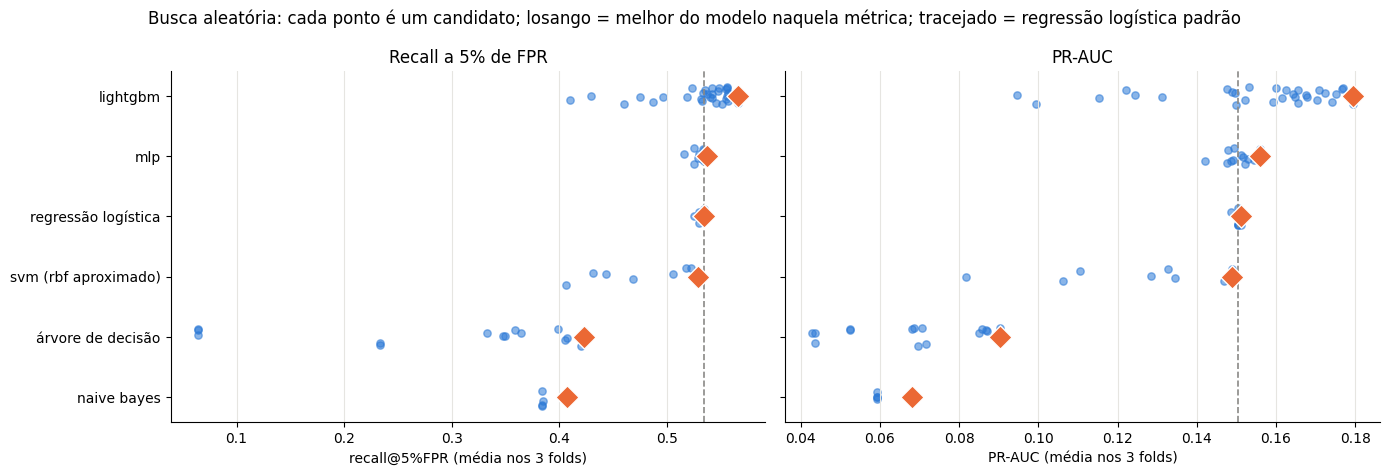

,recall@5%FPR média,recall@5%FPR desvio,PR-AUC média,ROC AUC média,segundos
id,,,,,
lightgbm #11,"0,5664","0,0242","0,1766","0,9080","81,0000"
mlp #02,"0,5371","0,0180","0,1529","0,8973","39,9000"
regressão logística #02,"0,5345","0,0199","0,1503","0,8964","19,1000"
svm (rbf aproximado) #02,"0,5292","0,0141","0,1468","0,8953","17,1000"
árvore de decisão #03,"0,4230","0,0159","0,0857","0,8106","42,4000"
naive bayes #02,"0,4069","0,0071","0,0680","0,8563","15,7000"


In [5]:
import matplotlib.pyplot as plt

R = "recall@5%FPR"
busca = pd.read_csv(ARQ_BUSCA)
ordem = busca.groupby("modelo")[f"{R} média"].max().sort_values().index  # pior embaixo, melhor em cima
logistica_padrao = busca.loc[busca["id"] == "regressão logística #04"].iloc[0]  # C ≈ 1, o padrão

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, metrica in zip(axes, [R, "PR-AUC"]):
    for y, modelo in enumerate(ordem):
        valores = busca.loc[busca["modelo"] == modelo, f"{metrica} média"]
        ax.scatter(valores, y + rng.uniform(-0.15, 0.15, len(valores)), s=28, color="#2a78d6", alpha=0.55)
        ax.scatter(valores.max(), y, s=140, marker="D", color="#eb6834", edgecolor="white", zorder=3)
    ax.axvline(logistica_padrao[f"{metrica} média"], color="#8a8986", ls="--", lw=1.2)
    ax.set_yticks(range(len(ordem)), ordem)
    ax.set_xlabel(f"{metrica} (média nos 3 folds)")
    ax.grid(axis="x", color="#e6e5e1")
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
axes[0].set_title("Recall a 5% de FPR")
axes[1].set_title("PR-AUC")
fig.suptitle("Busca aleatória: cada ponto é um candidato; losango = melhor do modelo naquela métrica; "
             "tracejado = regressão logística padrão")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_comparacao_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

colunas = ["id", f"{R} média", f"{R} desvio", "PR-AUC média", "ROC AUC média", "segundos"]
melhores = busca.loc[busca.groupby("modelo")[f"{R} média"].idxmax(), colunas] \
    .sort_values(f"{R} média", ascending=False).set_index("id")
melhores.style.format(precision=4, decimal=",")

**Conclusão:**

- **O LightGBM é o melhor modelo** em todas as métricas: recall a 5% de FPR de **0,566** (+0,032 sobre a regressão logística, ganho presente nos 3 folds: +0,031, +0,039, +0,026), PR-AUC de **0,177** (+17%) e ROC AUC de **0,908**. É um ganho 4× maior que a melhor mudança de pré-processamento do notebook 03 (+0,008): **o limite era mesmo o modelo**.
- **Rede neural (0,537) e SVM (0,529) empatam com a regressão logística** — coerente com o que se observa em dados tabulares, onde modelos de árvore com boosting costumam liderar.
- **Árvore de decisão (0,423) e Naive Bayes (0,407) ficam bem abaixo.** O Naive Bayes supõe variáveis independentes e normais, o que não vale aqui. A árvore isolada sofre com **empates**: com poucas folhas grandes, muitos pedidos recebem o mesmo score e o limiar de 5% de FPR cai no meio de uma folha — algumas árvores têm recall 0 em certos folds, mesmo com ROC AUC acima de 0,8.
- **Sensibilidade aos hiperparâmetros:** a logística quase não varia (o `C` não importa); LightGBM, SVM e árvore variam muito. Modelos mais flexíveis exigem busca.
- **Cuidado:** cada valor é o melhor de até 30 tentativas nos mesmos folds, o que embute algum otimismo. O desempenho honesto do modelo escolhido será medido uma única vez no teste (notebook 05).

## 4. LightGBM: o que importa nos hiperparâmetros

**Pergunta:** quais hiperparâmetros explicam a diferença entre os candidatos do LightGBM, e o undersampling ajuda?

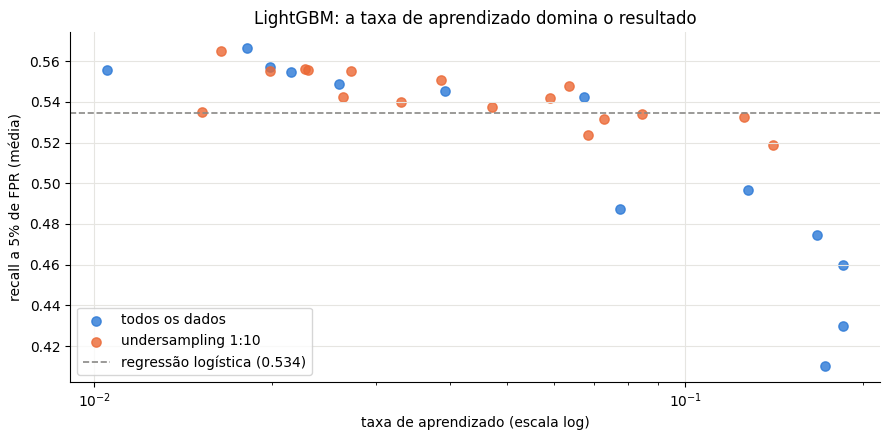

Correlação de Spearman de cada hiperparâmetro com o recall:
learning_rate       -0.87
min_child_samples   -0.19
colsample_bytree    -0.16
num_leaves          -0.15
reg_lambda          -0.07
n_estimators         0.11
scale_pos_weight     0.12
subsample            0.19


,candidatos,recall_mediana,recall_melhor,pr_auc_melhor,segundos_mediana
undersampling,,,,,
False,13,"0,5423","0,5664","0,1769","83,7000"
True,17,"0,5418","0,5648","0,1794","38,3000"


In [6]:
import ast

lgbm = busca[busca["modelo"] == "lightgbm"].reset_index(drop=True)
lgbm = pd.concat([lgbm, lgbm["params"].apply(ast.literal_eval).apply(pd.Series)], axis=1)

fig, ax = plt.subplots(figsize=(9, 4.5))
for usou, cor, nome in [(False, "#2a78d6", "todos os dados"), (True, "#eb6834", "undersampling 1:10")]:
    parte = lgbm[lgbm["undersampling"] == usou]
    ax.scatter(parte["learning_rate"], parte[f"{R} média"], s=45, color=cor, alpha=0.8, label=nome)
ax.axhline(logistica_padrao[f"{R} média"], color="#8a8986", ls="--", lw=1.2,
           label=f"regressão logística ({logistica_padrao[f'{R} média']:.3f})")
ax.set_xscale("log")
ax.set_xlabel("taxa de aprendizado (escala log)")
ax.set_ylabel("recall a 5% de FPR (média)")
ax.set_title("LightGBM: a taxa de aprendizado domina o resultado")
ax.legend(loc="lower left")
ax.grid(color="#e6e5e1")
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_lightgbm_taxa_aprendizado.png", dpi=150, bbox_inches="tight")
plt.show()

hiperparametros = ["learning_rate", "n_estimators", "num_leaves", "min_child_samples",
                   "scale_pos_weight", "subsample", "colsample_bytree", "reg_lambda"]
print("Correlação de Spearman de cada hiperparâmetro com o recall:")
print(lgbm[hiperparametros].corrwith(lgbm[f"{R} média"], method="spearman")
      .sort_values().round(2).to_string())

lgbm.groupby("undersampling").agg(
    candidatos=("id", "size"),
    recall_mediana=(f"{R} média", "median"),
    recall_melhor=(f"{R} média", "max"),
    pr_auc_melhor=("PR-AUC média", "max"),
    segundos_mediana=("segundos", "median"),
).style.format(precision=4, decimal=",")

**Conclusão:**

- **A taxa de aprendizado domina:** correlação de Spearman de -0,87 com o recall. Os demais hiperparâmetros têm efeito fraco (|ρ| ≤ 0,19), inclusive o `scale_pos_weight` (peso da classe rara).
- Com **todos os dados e taxa alta** (> ~0,07), o desempenho despenca (recall de 0,41 a 0,50): passos grandes com centenas de árvores levam ao **sobreajuste**. Com undersampling, a mesma faixa de taxas degrada bem menos (0,52 a 0,55).
- **Undersampling × todos os dados: empate.** Melhor recall de 0,565 contra 0,566, medianas idênticas (0,542) e PR-AUC ligeiramente melhor com undersampling (0,179 vs. 0,177). A hipótese de que o undersampling prejudicaria o LightGBM **não se confirmou**; a de que ajudaria (vista com os hiperparâmetros padrão) também não, depois de ajustar os hiperparâmetros.
- O undersampling traz duas vantagens práticas: **treino ~2× mais rápido** (mediana de 38 s contra 84 s nos 3 folds) e **mais tolerância** a uma taxa de aprendizado mal escolhida.
- Os dois melhores candidatos — **#11** (todos os dados) e **#19** (undersampling) — são equivalentes no recall; a escolha entre eles vem da seção seguinte.

## 5. Ponto de operação dos finalistas

A mesma análise da seção 7 do notebook 02, para o melhor candidato de cada modelo competitivo e para os dois melhores LightGBM (com e sem undersampling):

1. **Estabilidade:** com o limiar fixado no treino de cada fold (5% de FPR), qual a FPR e o recall **realizados** no mês seguinte?
2. **Justiça:** no limiar de 5% de FPR global (calibrado na própria validação), a FPR de legítimos com 50 anos ou mais vs. menos de 50, e a razão entre elas (1 = igualdade).

In [7]:
from src.validacao import gerar_folds, limiar_para_fpr, nome_fold, taxas
from src.experimentos import pontuar

FINALISTAS = ["lightgbm #11", "lightgbm #19", "mlp #02", "regressão logística #04", "svm (rbf aproximado) #02"]
candidatos_por_id = {c["id"]: c for c in CANDIDATOS}


def operacao(candidato, df):
    """Estabilidade do limiar e justiça por idade, fold a fold (mesma lógica do notebook 02)."""
    linhas = []
    for meses_tr, mes_val, idx_tr, idx_val in gerar_folds(df):
        X_tr, y_tr = limpar(df.loc[idx_tr]), df.loc[idx_tr, ALVO].to_numpy()
        X_va, y_va = limpar(df.loc[idx_val]), df.loc[idx_val, ALVO].to_numpy()
        pipe = FABRICAS[candidato["modelo"]](**candidato["params"])
        pipe.fit(X_tr, y_tr)
        s_tr, s_va = pontuar(pipe, X_tr), pontuar(pipe, X_va)

        real = taxas(y_va, s_va, limiar_para_fpr(y_tr, s_tr))  # limiar fixado no passado
        limiar_ideal = limiar_para_fpr(y_va, s_va)               # calibrado no próprio mês
        mais_50 = (df.loc[idx_val, "customer_age"] >= 50).to_numpy()
        fpr_menos = taxas(y_va[~mais_50], s_va[~mais_50], limiar_ideal)["FPR"]
        fpr_mais = taxas(y_va[mais_50], s_va[mais_50], limiar_ideal)["FPR"]
        linhas.append({"fold": nome_fold(meses_tr, mes_val),
                       "FPR realizada": real["FPR"], "recall realizado": real["recall"],
                       "FPR < 50 anos": fpr_menos, "FPR ≥ 50 anos": fpr_mais,
                       "razão de FPR": min(fpr_menos, fpr_mais) / max(fpr_menos, fpr_mais)})
    return pd.DataFrame(linhas).set_index("fold")


resumo = []
for id_ in FINALISTAS:
    op = operacao(candidatos_por_id[id_], treino)
    resumo.append({
        "modelo": id_,
        "FPR realizada (folds)": " / ".join(f"{v:.1%}" for v in op["FPR realizada"]),
        "maior desvio da FPR (p.p.)": 100 * (op["FPR realizada"] - 0.05).abs().max(),
        "recall realizado (média)": op["recall realizado"].mean(),
        "FPR < 50 anos": op["FPR < 50 anos"].mean(),
        "FPR ≥ 50 anos": op["FPR ≥ 50 anos"].mean(),
        "razão de FPR": op["razão de FPR"].mean(),
    })
    print(f"{id_}: ok")

operacao_finalistas = pd.DataFrame(resumo).set_index("modelo")
operacao_finalistas.to_csv(RAIZ / "reports" / "operacao_04_finalistas.csv", float_format="%.4f")
operacao_finalistas.style.format(precision=3, decimal=",")

lightgbm #11: ok
lightgbm #19: ok
mlp #02: ok
regressão logística #04: ok
svm (rbf aproximado) #02: ok


,FPR realizada (folds),maior desvio da FPR (p.p.),recall realizado (média),FPR < 50 anos,FPR ≥ 50 anos,razão de FPR
modelo,,,,,,
lightgbm #11,8.9% / 6.5% / 4.1%,"3,886","0,620","0,035","0,118","0,295"
lightgbm #19,9.2% / 6.7% / 4.1%,"4,221","0,618","0,036","0,115","0,311"
mlp #02,7.4% / 6.2% / 3.6%,"2,370","0,567","0,033","0,125","0,267"
regressão logística #04,7.6% / 6.0% / 3.2%,"2,617","0,552","0,034","0,123","0,277"
svm (rbf aproximado) #02,8.3% / 6.6% / 3.7%,"3,259","0,568","0,032","0,130","0,247"


**Conclusão:**

- **A instabilidade do limiar afeta todos os modelos da mesma forma:** FPR realizada alta no fold 1 (7,4% a 9,2%), próxima de 5% no fold 2 e baixa no fold 3 (3,2% a 4,1%). Como o padrão é comum, a causa é a **mudança nos dados** entre os meses (o fold 1 valida no mês 3, onde o `credit_risk_score` muda de patamar), não um defeito de algum modelo.
- **O LightGBM é o mais sensível ao drift** (até 4,2 p.p. de desvio, contra 2,4–2,6 p.p. da MLP e da logística): o modelo mais flexível aproveita mais os detalhes das variáveis, inclusive das que mudam no tempo. Precisão e estabilidade entram em conflito.
- O "recall realizado" mistura desempenho e desvio de FPR (o fold 1 barra mais legítimos que o planejado); para comparar recall, vale o da busca, a 5% de FPR exatos.
- **Justiça por idade: nenhum modelo resolve.** A razão de FPR fica entre 0,25 e 0,31 em todos (legítimos com 50+ anos barrados ~3,5× mais). O LightGBM é ligeiramente menos desigual (0,30–0,31) que a logística (0,28) e a SVM (0,25). A causa está nos dados — a taxa de fraude maior nesse grupo —, não no algoritmo.

## 6. Resumo e escolha do modelo final

| Modelo (melhor candidato) | Recall a 5% FPR | PR-AUC | ROC AUC |
|---|---|---|---|
| **LightGBM #11** | **0,566** | **0,177** | **0,908** |
| MLP #02 | 0,537 | 0,153 | 0,897 |
| Regressão logística | 0,534 | 0,150 | 0,896 |
| SVM (RBF aproximado) #02 | 0,529 | 0,147 | 0,895 |
| Árvore de decisão #03 | 0,423 | 0,086 | 0,811 |
| Naive Bayes #02 | 0,407 | 0,068 | 0,856 |

*Média nos 3 folds temporais; melhor de cada modelo na busca aleatória (80 candidatos no total).*

- **Modelo escolhido: LightGBM #11** (todos os dados, sem undersampling; taxa de aprendizado ≈ 0,018, 518 árvores, 47 folhas, `scale_pos_weight` = 3). O #19 (com undersampling) é equivalente no recall, mas o #11 produz **probabilidades na escala real** (o undersampling infla a proporção de fraudes no treino e distorce as probabilidades), o que importa para interpretá-las em produção, e tem um componente a menos no pipeline.
- **Ganho sobre a régua:** +0,032 de recall e +17% de PR-AUC, consistente nos 3 folds.
- **Pontos de atenção para o modelo final:** o LightGBM é o mais sensível ao drift (FPR realizada de 8,9% / 6,5% / 4,1% com limiar fixo) e mantém a desigualdade por idade (razão de FPR de ~0,30).
- Resultados em `reports/busca_04_modelos.csv` e `reports/operacao_04_finalistas.csv`.

**Próximo passo:** `05_modelo_final.ipynb` — treinar o LightGBM #11 nos meses 0–5, avaliá-lo **uma única vez** no teste (meses 6–7), comparar políticas de limiar diante do drift, analisar justiça por idade, interpretar com SHAP e salvar o modelo.